<a href="https://colab.research.google.com/github/2303880-Mandi/Bridging-Theory-and-Practice-in-Kernel-Based-Dequantization-of-VQML/blob/main/NASA_Airfoil_Self_Noise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NASA Airfoil Self-Noise: PQC vs KRR vs KTA-weighted KRR

Compares a trained re-uploading PQC, KRR with the uniform-weight PQC kernel, and KRR with a KTA-learned product-form re-weighted kernel ($d=5$, $L=5$), exactly as in the California Housing notebook, on the NASA Airfoil Self-Noise regression task.

## The dataset

**Origin.** Brooks, Pope and Marcolini (NASA, 1989): aerofoil sections of different sizes were tested in the anechoic wind tunnel at NASA Langley Research Center at several wind speeds and angles of attack, and the noise each section produced *by itself* (self-noise, mainly turbulent boundary-layer and trailing-edge noise) was measured. The data are distributed through the UCI Machine Learning Repository.

**Size.** 1503 samples, **5 features** and **1 label**, no missing values.

| # | Feature | Unit | Range / values | Physical meaning |
|---|---------|------|----------------|------------------|
| 1 | `frequency` | Hz | 200 to 20 000 (21 one-third-octave bands) | Frequency of the sound being measured |
| 2 | `angle` | degrees | 0 to 22.2 | Angle of attack between the aerofoil chord and the oncoming flow |
| 3 | `chord` | m | 0.0254 to 0.3048 (6 values) | Chord length (aerofoil size) |
| 4 | `velocity` | m/s | 31.7, 39.6, 55.5, 71.3 | Free-stream (tunnel) velocity |
| 5 | `thickness` | m | about 0.0004 to 0.058 | Suction-side displacement thickness: how thick the boundary layer is on the upper surface near the trailing edge |

**Label.** `spl`, the *scaled sound pressure level* in decibels (dB), roughly 103 to 140 dB. It is the measured noise level with the effect of the tunnel/measurement set-up scaled out, so that it is comparable across runs. This is the quantity to predict.

**Why it matters.** Blade and wing noise is a driver of community noise limits for aircraft and helicopters and of siting constraints for wind turbines. A model that predicts self-noise from geometry and flow conditions can be used in the design stage instead of repeating wind-tunnel campaigns. The response is smooth and physically structured, with a mixture of continuous features (frequency, thickness) and a few discrete ones (velocity, chord, angle), which makes it a convenient real-world test for low-frequency Fourier models.

**Feature importance.** Frequency and the boundary-layer thickness (which itself depends on chord, angle and velocity) carry most of the signal, while velocity on its own is comparatively weak; the Spearman correlations computed below give a first, purely monotone, view of this. KTA gives a second, model-based view through the learned per-feature frequency weights in the last figure.

**Caveats.** Only 4 velocities, 6 chords and about 15 angles occur, so the 1503 rows come from a small set of aerofoil/flow configurations. A random split therefore puts near-identical configurations in both the training and test sets, and the reported error is optimistic compared with predicting for an unseen configuration. Report it as such, or use a split by configuration as a stricter check.

**Preprocessing.** `frequency` and `thickness` are transformed with $\log_{10}$ (they span one to two orders of magnitude), then all features are clipped to the training 1st-99th percentiles and rescaled to $[0,\pi]$. The target is rescaled to $[-1,1]$ to match the range of $\langle Z_0\rangle$. Scaling constants are fitted on the training split only. All plots show SPL in dB via `to_price`, which inverts the scaling and clips to the observed training range.

**Data file.** Place `airfoil_self_noise.dat` (tab-separated, no header, 6 columns in the order above with SPL last) next to the notebook, or set the environment variable `AIRFOIL_PATH`.

In [1]:
!pip install pennylane -q

In [2]:
import os, time, json, itertools
import numpy as np
import matplotlib
matplotlib.use("Agg") if os.environ.get("HEADLESS") else None
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp
import autograd.numpy as anp
from autograd import grad
from scipy.optimize import minimize
from sklearn.kernel_ridge import KernelRidge

# colours: PQC = purple, KRR with uniform w = green, KRR with KTA-learned w = blue
PQC_COLOR     = "#7B2CBF"
KRR_COLOR     = "#1F5FD1"   # KRR with KTA-learned w
KRR_UNI_COLOR = "#2E9E4F"   # KRR with uniform w (green)
plt.rcParams.update({
    "font.size": 16, "axes.titlesize": 18, "axes.labelsize": 17,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 15, "legend.frameon": True, "legend.framealpha": 0.95, "legend.edgecolor": "0.3",
    "axes.linewidth": 1.4, "figure.dpi": 100,
})
os.makedirs("figures", exist_ok=True)

## 1. Configuration

In [3]:
SEED = 0
D = 5                       # number of features = number of qubits
L = 5                       # R_X re-uploads per feature -> integer frequencies {-L..L}
FEATURES = ["frequency", "angle", "chord", "velocity", "thickness"]

N_TRAIN, N_VAL, N_TEST = 1000, 200, 300
N_KTA = 1000                  # training points used to evaluate KTA (cost grows as N_KTA^2)
KTA_RESTARTS = 5
SWEEP = [50, 100, 250, 500, 1000]                  # training-set sizes for the learning curve
SWEEP_RESTARTS = 2
LAMBDAS = [1e-12, 1e-10, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

PQC_BLOCK_LAYERS = 1        # StronglyEntanglingLayers per trainable block
PQC_STEPS, PQC_BATCH, PQC_LR = 300, 100, 0.05

PREFIX = "airfoil"          # figure file prefix
assert len(FEATURES) == D
n_total = (2*L + 1)**D
print(f"Full spectrum: {n_total} frequencies; |Omega_D| = {(n_total - 1)//2 + 1}")

Full spectrum: 161051 frequencies; |Omega_D| = 80526


## 2. Data

See the dataset description above. Split: 1000 train / 200 validation / 300 test (1500 of the 1503 samples), shuffled with a fixed seed.

In [4]:
AIRFOIL_PATH = os.environ.get("AIRFOIL_PATH", "airfoil_self_noise.dat")   # UCI file: 6 tab-separated columns, no header
AIRFOIL_NAMES = ["frequency", "angle", "chord", "velocity", "thickness", "spl"]
LOG_FEATURES = ["frequency", "thickness"]    # span 1-2 orders of magnitude -> use log10 so angles are not crowded at one end

def load_raw():
    if os.environ.get("SYNTHETIC_SMOKE_TEST"):          # only used to test the code path offline
        r = np.random.default_rng(0); n = 1503
        f = r.choice([200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000,5000,6300,8000,10000,12500,16000,20000], n)
        a = r.choice([0,1.5,3,4,5.4,6.7,7.2,8.4,9.9,11.2,12.3,15.4,17.4,19.7,22.2], n)
        c = r.choice([0.0254,0.0508,0.1016,0.1524,0.2286,0.3048], n); v = r.choice([31.7,39.6,55.5,71.3], n)
        t = 1e-3 * (1 + a) * (0.3048 / (c * 5 + 0.1)) * r.uniform(.3, 1.2, n) * 0.1
        y = 130 - 6*np.log10(f/1000) - 0.4*a - 20*c + 0.08*v + r.normal(0, 1.5, n)
        data = np.column_stack([f, a, c, v, t, y])
    elif os.path.exists(AIRFOIL_PATH):
        data = np.loadtxt(AIRFOIL_PATH)
    else:
        raise FileNotFoundError(f"{AIRFOIL_PATH} not found. Download airfoil_self_noise.dat from the UCI repository "
                                "(NASA Airfoil Self-Noise) and place it next to the notebook, or set AIRFOIL_PATH.")
    assert data.shape[1] == 6, data.shape
    X, y = data[:, :5].copy(), data[:, 5]
    for f_ in LOG_FEATURES:
        X[:, AIRFOIL_NAMES.index(f_)] = np.log10(X[:, AIRFOIL_NAMES.index(f_)])
    return X, y, AIRFOIL_NAMES[:5]

rng = np.random.default_rng(SEED)
X_all, y_all, names = load_raw()
cols = [names.index(f) for f in FEATURES]
X_all = X_all[:, cols]

assert N_TRAIN + N_VAL + N_TEST <= len(y_all)

perm = rng.permutation(len(y_all))
i_te = perm[:N_TEST]
i_va = perm[N_TEST:N_TEST + N_VAL]
i_tr = perm[N_TEST + N_VAL:N_TEST + N_VAL + N_TRAIN]

lo, hi = np.percentile(X_all[i_tr], [1, 99], axis=0)
def prep_X(X):
    return (np.clip(X, lo, hi) - lo) / (hi - lo) * np.pi        # -> [0, pi]

ymin, ymax = y_all[i_tr].min(), y_all[i_tr].max()
def prep_y(y):
    return 2 * (y - ymin) / (ymax - ymin) - 1                     # -> [-1, 1]

Xtr, Xva, Xte = prep_X(X_all[i_tr]), prep_X(X_all[i_va]), prep_X(X_all[i_te])
ytr, yva, yte = prep_y(y_all[i_tr]), prep_y(y_all[i_va]), prep_y(y_all[i_te])

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))
to_units = lambda r: r * (ymax - ymin) / 2                        # RMSE in scaled units -> target units
# scaled output in [-1, 1] -> sound pressure level in target units.
# The map is affine onto [ymin, ymax] and then clipped, so predictions can never leave the observed
# training range (SPL is positive, about 103 to 140 dB).
to_price = lambda r: np.clip(ymin + (np.asarray(r, float) + 1) * (ymax - ymin) / 2, ymin, ymax)
print("train/val/test:", Xtr.shape, Xva.shape, Xte.shape)
print("target range in training data:", round(ymin, 3), "to", round(ymax, 3))
print("baseline RMSE (predict the training mean):",
      round(to_units(rmse(yte, ytr.mean())), 4), "dB")

train/val/test: (1000, 5) (200, 5) (300, 5)
target range in training data: 104.13 to 140.158
baseline RMSE (predict the training mean): 7.3775 dB


### Feature-target relationships (training split)

In [5]:
from scipy.stats import spearmanr
print(f"{'feature':12s} {'Spearman rho vs SPL':>20s}   (training split, features after the log transform)")
for j, f_ in enumerate(FEATURES):
    rho = spearmanr(X_all[i_tr, j], y_all[i_tr])[0]
    print(f"{f_:12s} {rho:20.3f}")
print("distinct values: velocity", len(np.unique(X_all[:, 3])), "| chord", len(np.unique(X_all[:, 2])), "| angle", len(np.unique(X_all[:, 1])))

feature       Spearman rho vs SPL   (training split, features after the log transform)
frequency                  -0.345
angle                      -0.136
chord                      -0.229
velocity                    0.124
thickness                  -0.260
distinct values: velocity 4 | chord 6 | angle 27


## 3. Product-structured PQC kernel

Each feature $j$ has a symmetric distribution over $\{-L,\dots,L\}$, parametrised by $L+1$ logits (softmax) over $|k|=0,\dots,L$. The full kernel is the element-wise product over features:
$$K_{(\mathcal{D},w)}(x,x')=\prod_{j=1}^{d}\sum_{k=-L}^{L}p_j(k)\cos\bigl(k(x_j-x_j')\bigr).$$

In [6]:
def feat(xj, L):
    # xj: (n,) -> (n, 2L+1) = [1, cos(kx)_{k=1..L}, sin(kx)_{k=1..L}]
    kx = np.outer(xj, np.arange(1, L + 1))
    return np.hstack([np.ones((len(xj), 1)), np.cos(kx), np.sin(kx)])

def make_feats(X, L):
    return [feat(X[:, j], L) for j in range(X.shape[1])]

def weights_from_logits(lg):
    e = anp.exp(lg - anp.max(lg))
    u = e / anp.sum(e)                                   # u_0..u_L, sums to 1
    return anp.concatenate([u[:1], u[1:], u[1:]])

def gram(F1, F2, logits):
    K = 1.0
    for j in range(len(F1)):
        w = weights_from_logits(logits[j])
        K = K * ((F1[j] * w) @ F2[j].T)
    return K

# uniform p_j over {-L..L}: u_0 = 1/(2L+1), u_k = 2/(2L+1)  <=>  w = (1,...,1)
UNIFORM_LOGITS = np.tile(np.log(np.array([1.0] + [2.0] * L)), (D, 1))

# Sanity check: product formula == brute-force sum over the whole product spectrum (small case)
def brute_force_kernel(X1, X2, logits, L):
    Dd = logits.shape[0]
    ks = np.arange(-L, L + 1)
    P = []
    for j in range(Dd):
        u = np.exp(logits[j]); u = u / u.sum()
        p = np.empty(2*L + 1); p[L] = u[0]
        for k in range(1, L + 1):
            p[L + k] = p[L - k] = u[k] / 2
        P.append(p)
    K = np.zeros((len(X1), len(X2)))
    for idx in itertools.product(range(2*L + 1), repeat=Dd):
        om = ks[list(idx)]
        K += np.prod([P[j][idx[j]] for j in range(Dd)]) * np.cos((X1[:, None, :] - X2[None, :, :]) @ om)
    return K

r = np.random.default_rng(1)
Xa, Xb = r.uniform(0, np.pi, (20, 2)), r.uniform(0, np.pi, (15, 2))
lg = r.normal(size=(2, 3))
K_fast = gram(make_feats(Xa, 2), make_feats(Xb, 2), lg)
K_brute = brute_force_kernel(Xa, Xb, lg, 2)
print("max |product - brute force| =", np.abs(K_fast - K_brute).max())
assert np.abs(K_fast - K_brute).max() < 1e-12
print("diag(K) == 1:", np.allclose(np.diag(gram(make_feats(Xa, 2), make_feats(Xa, 2), lg)), 1.0))

max |product - brute force| = 5.551115123125783e-16
diag(K) == 1: True


## 4. Kernel ridge regression

In [7]:
def krr_predict(Ktr, Kxt, y, lam):
    n = len(y)
    alpha = np.linalg.solve(Ktr + n * lam * np.eye(n), y)
    return np.clip(Kxt @ alpha, -1, 1)      # keep predictions inside the training target range

def eval_weights(logits, Ftr, ytr, Fva, yva, Fte, yte):
    Ktr, Kva, Kte = gram(Ftr, Ftr, logits), gram(Fva, Ftr, logits), gram(Fte, Ftr, logits)
    best = min(((rmse(krr_predict(Ktr, Kva, ytr, lam), yva), lam) for lam in LAMBDAS))
    pte = krr_predict(Ktr, Kte, ytr, best[1])
    return dict(lam=best[1], val_rmse=best[0], test_rmse=rmse(pte, yte), pred=pte)

def eval_rbf(Xtr, ytr, Xva, yva, Xte, yte):
    best = None
    for g in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]:
        for a in LAMBDAS:
            m = KernelRidge(kernel="rbf", gamma=g, alpha=a * len(ytr)).fit(Xtr, ytr)
            r_ = rmse(np.clip(m.predict(Xva), -1, 1), yva)
            if best is None or r_ < best[0]:
                best = (r_, g, a, m)
    pte = np.clip(best[3].predict(Xte), -1, 1)
    return dict(gamma=best[1], lam=best[2], val_rmse=best[0], test_rmse=rmse(pte, yte), pred=pte)

## 5. Kernel target alignment

Centred alignment maximised over the product-weight logits with exact autograd gradients and L-BFGS-B, with random restarts.

In [8]:
def centered(K):
    return K - anp.mean(K, axis=0, keepdims=True) - anp.mean(K, axis=1, keepdims=True) + anp.mean(K)

def alignment(logits, F, y):
    yc = y - y.mean()
    Y = np.outer(yc, yc)
    K = centered(gram(F, F, logits))
    return float(np.sum(K * Y) / (np.sqrt(np.sum(K * K)) * np.sqrt(np.sum(Y * Y))))

def learn_weights(F, y, restarts, seed=0, verbose=True):
    Dd, Lp1 = len(F), F[0].shape[1] // 2 + 1
    yc = y - y.mean()
    Y = np.outer(yc, yc); Ynorm = np.sqrt(np.sum(Y * Y))
    def loss(flat):
        K = centered(gram(F, F, flat.reshape(Dd, Lp1)))
        return -anp.sum(K * Y) / (anp.sqrt(anp.sum(K * K)) * Ynorm)
    g = grad(loss)
    r = np.random.default_rng(seed)
    base = np.tile(np.log(np.array([1.0] + [2.0] * (Lp1 - 1))), (Dd, 1))
    runs = []
    for i in range(restarts):
        x0 = (base if i == 0 else base + r.normal(size=base.shape)).ravel()   # restart 0 = uniform start
        t0 = time.time()
        res = minimize(loss, x0, jac=g, method="L-BFGS-B",
                       bounds=[(-12, 12)] * x0.size, options={"maxiter": 200})
        runs.append((-res.fun, res.x.reshape(Dd, Lp1)))
        if verbose:
            print(f"  restart {i}: alignment {-res.fun:.4f}  ({time.time() - t0:.0f}s)")
    return sorted(runs, key=lambda t: -t[0])

## 6. The PQC

Five qubits, one per feature, each uploaded $L$ times with $R_X(x_j)$, interleaved with trainable `StronglyEntanglingLayers`; observable $Z_0$.

In [9]:
dev = qml.device("default.qubit", wires=D)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def circuit(weights, x):
    # x has shape (batch, D); weights has shape (L+1, PQC_BLOCK_LAYERS, D, 3)
    for r in range(L):
        qml.StronglyEntanglingLayers(weights[r], wires=range(D))
        for j in range(D):
            qml.RX(x[:, j], wires=j)
    qml.StronglyEntanglingLayers(weights[L], wires=range(D))
    return qml.expval(qml.PauliZ(0))

def pqc_predict(w, X, chunk=500):
    return np.concatenate([np.asarray(circuit(w, X[i:i + chunk])) for i in range(0, len(X), chunk)])

def make_cost(xb, yb):
    # data are captured in a closure so that only the circuit weights are trainable
    return lambda w_: pnp.mean((circuit(w_, xb) - yb) ** 2)

pr = np.random.default_rng(SEED)
w = pnp.array(pr.uniform(0, 2*np.pi, size=(L + 1, PQC_BLOCK_LAYERS, D, 3)), requires_grad=True)
opt = qml.AdamOptimizer(stepsize=PQC_LR)

hist = []
t0 = time.time()
for step in range(PQC_STEPS):
    idx = pr.choice(len(ytr), size=min(PQC_BATCH, len(ytr)), replace=False)
    xb = pnp.array(Xtr[idx], requires_grad=False)
    yb = pnp.array(ytr[idx], requires_grad=False)
    w, c = opt.step_and_cost(make_cost(xb, yb), w)
    if step % max(1, PQC_STEPS // 10) == 0 or step == PQC_STEPS - 1:
        hist.append((step, rmse(pqc_predict(w, Xtr), ytr), rmse(pqc_predict(w, Xva), yva)))
        print(f"step {step:4d}  train RMSE {hist[-1][1]:.4f}  val RMSE {hist[-1][2]:.4f}  ({time.time() - t0:.0f}s)")

pqc_pred_te = pqc_predict(w, Xte)
pqc_res = dict(val_rmse=rmse(pqc_predict(w, Xva), yva), test_rmse=rmse(pqc_pred_te, yte))
print("PQC test RMSE:", round(pqc_res["test_rmse"], 4), f"(= {to_units(pqc_res['test_rmse']):.4f} dB)")

# Sanity check on the spectrum: as a function of ONE feature (others fixed) the PQC output
# should be a trigonometric polynomial of degree <= L. Check the FFT leakage above frequency L.
N = 64
scan = np.linspace(0, 2*np.pi, N, endpoint=False)
base = np.random.default_rng(5).uniform(0, np.pi, size=D)
for j in range(D):
    Xs = np.tile(base, (N, 1)); Xs[:, j] = scan
    c = np.fft.rfft(pqc_predict(w, Xs)) / N
    print(f"feature {j}: max |c_k| for k<={L}: {np.abs(c[:L+1]).max():.3e},  "
          f"max |c_k| for k>{L}: {np.abs(c[L+1:]).max():.2e}")

step    0  train RMSE 0.4079  val RMSE 0.4234  (1s)
step   30  train RMSE 0.2535  val RMSE 0.2592  (13s)
step   60  train RMSE 0.2307  val RMSE 0.2518  (26s)
step   90  train RMSE 0.2081  val RMSE 0.2357  (30s)
step  120  train RMSE 0.1998  val RMSE 0.2238  (36s)
step  150  train RMSE 0.1916  val RMSE 0.2289  (41s)
step  180  train RMSE 0.1886  val RMSE 0.2311  (45s)
step  210  train RMSE 0.1884  val RMSE 0.2364  (51s)
step  240  train RMSE 0.1834  val RMSE 0.2283  (56s)
step  270  train RMSE 0.1866  val RMSE 0.2252  (60s)
step  299  train RMSE 0.1803  val RMSE 0.2165  (66s)
PQC test RMSE: 0.2249 (= 4.0513 dB)
feature 0: max |c_k| for k<=5: 9.411e-02,  max |c_k| for k>5: 5.50e-17
feature 1: max |c_k| for k<=5: 5.309e-02,  max |c_k| for k>5: 3.24e-17
feature 2: max |c_k| for k<=5: 7.339e-02,  max |c_k| for k>5: 4.57e-17
feature 3: max |c_k| for k<=5: 1.276e-01,  max |c_k| for k>5: 4.51e-17
feature 4: max |c_k| for k<=5: 8.269e-02,  max |c_k| for k>5: 3.94e-17


## 7. Main comparison: PQC vs KRR (uniform $w$) vs KRR (KTA $w$)

In [10]:
Ftr, Fva, Fte = make_feats(Xtr, L), make_feats(Xva, L), make_feats(Xte, L)

# --- KRR with uniform weights
uni = eval_weights(UNIFORM_LOGITS, Ftr, ytr, Fva, yva, Fte, yte)
uni["align"] = alignment(UNIFORM_LOGITS, [F[:N_KTA] for F in Ftr], ytr[:N_KTA])

# --- KTA: learn w on the first N_KTA training points, then fit KRR on all training points
print("Learning w with KTA ...")
runs = learn_weights([F[:N_KTA] for F in Ftr], ytr[:N_KTA], KTA_RESTARTS, seed=SEED)
kta_logits = runs[0][1]
kta = eval_weights(kta_logits, Ftr, ytr, Fva, yva, Fte, yte)
kta["align"] = runs[0][0]

# --- reference
rbf = eval_rbf(Xtr, ytr, Xva, yva, Xte, yte)

rows = [("PQC", pqc_res["val_rmse"], pqc_res["test_rmse"], None, None),
        ("KRR, uniform w", uni["val_rmse"], uni["test_rmse"], uni["lam"], uni["align"]),
        ("KRR, KTA w", kta["val_rmse"], kta["test_rmse"], kta["lam"], kta["align"]),
        ("KRR, RBF (reference)", rbf["val_rmse"], rbf["test_rmse"], rbf["lam"], None)]
print(f"\n{'model':24s} {'val RMSE':>9s} {'test RMSE':>10s} {'test (dB)':>14s} {'lambda':>8s} {'align':>7s}")
for name, v, t, lam, al in rows:
    print(f"{name:24s} {v:9.4f} {t:10.4f} {to_units(t):14.4f} "
          f"{'' if lam is None else format(lam, '.0e'):>8s} {'' if al is None else format(al, '.3f'):>7s}")

Learning w with KTA ...
  restart 0: alignment 0.2593  (5s)
  restart 1: alignment 0.2255  (18s)
  restart 2: alignment 0.2699  (20s)
  restart 3: alignment 0.2687  (12s)
  restart 4: alignment 0.2699  (24s)

model                     val RMSE  test RMSE      test (dB)   lambda   align
PQC                         0.2165     0.2249         4.0513                 
KRR, uniform w              0.1162     0.1277         2.3010    1e-05   0.052
KRR, KTA w                  0.1070     0.1030         1.8561    1e-10   0.270
KRR, RBF (reference)        0.1006     0.1025         1.8468    1e-05        


## 8. Learning curve in the number of training points

In [11]:
sweep_res = []
for n in SWEEP:
    Fn = [F[:n] for F in Ftr]
    u = eval_weights(UNIFORM_LOGITS, Fn, ytr[:n], Fva, yva, Fte, yte)
    rs = learn_weights([F[:min(n, N_KTA)] for F in Ftr], ytr[:min(n, N_KTA)],
                       SWEEP_RESTARTS, seed=SEED, verbose=False)
    k = eval_weights(rs[0][1], Fn, ytr[:n], Fva, yva, Fte, yte)
    sweep_res.append((n, u["test_rmse"], k["test_rmse"], rs[0][0]))
    print(f"n={n:5d}  uniform {u['test_rmse']:.4f}   KTA {k['test_rmse']:.4f}   (alignment {rs[0][0]:.3f})")

n=   50  uniform 0.4151   KTA 0.2368   (alignment 0.378)
n=  100  uniform 0.4116   KTA 0.1928   (alignment 0.312)
n=  250  uniform 0.3257   KTA 0.1872   (alignment 0.332)
n=  500  uniform 0.2486   KTA 0.1258   (alignment 0.290)
n= 1000  uniform 0.1277   KTA 0.1029   (alignment 0.259)


## 9. Figures and saved results

test R^2:  PQC 0.698 | KRR uniform 0.903 | KRR KTA 0.937 | KRR RBF 0.937


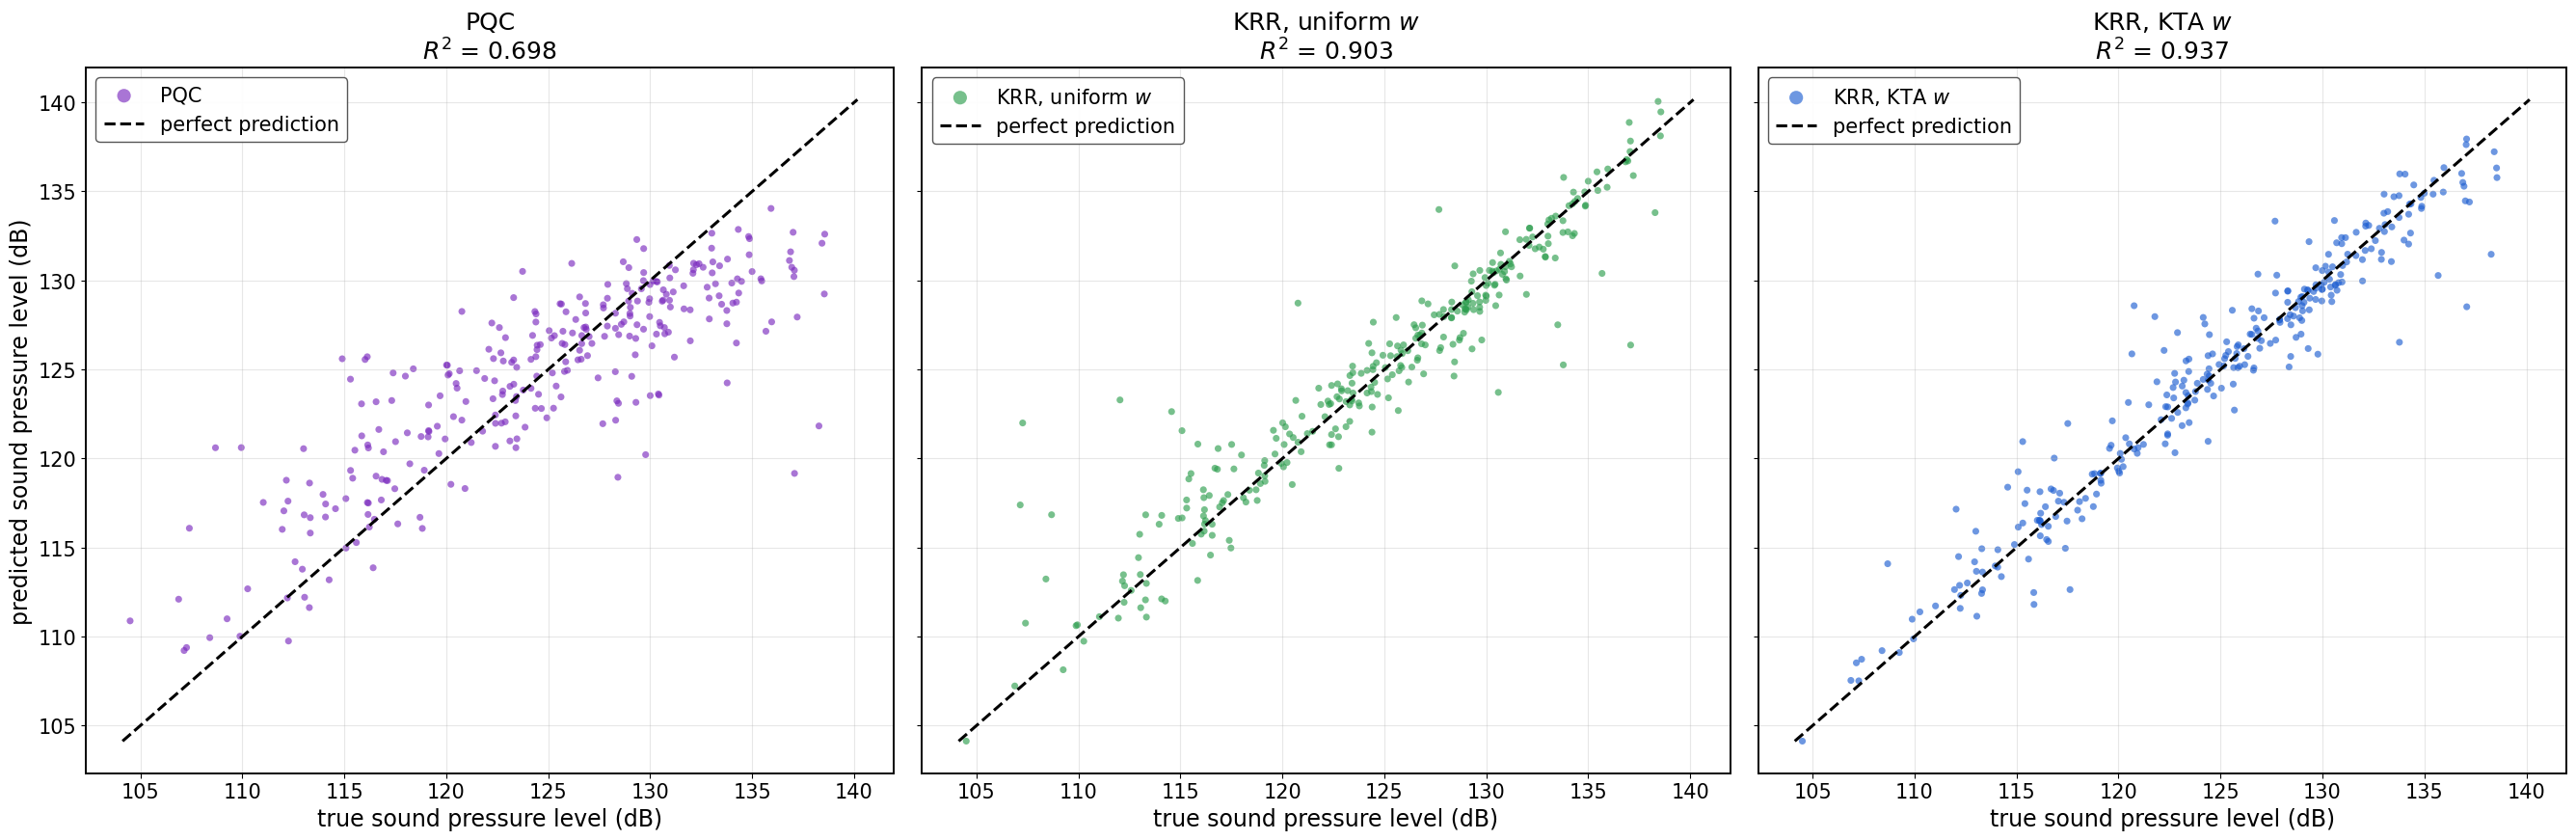

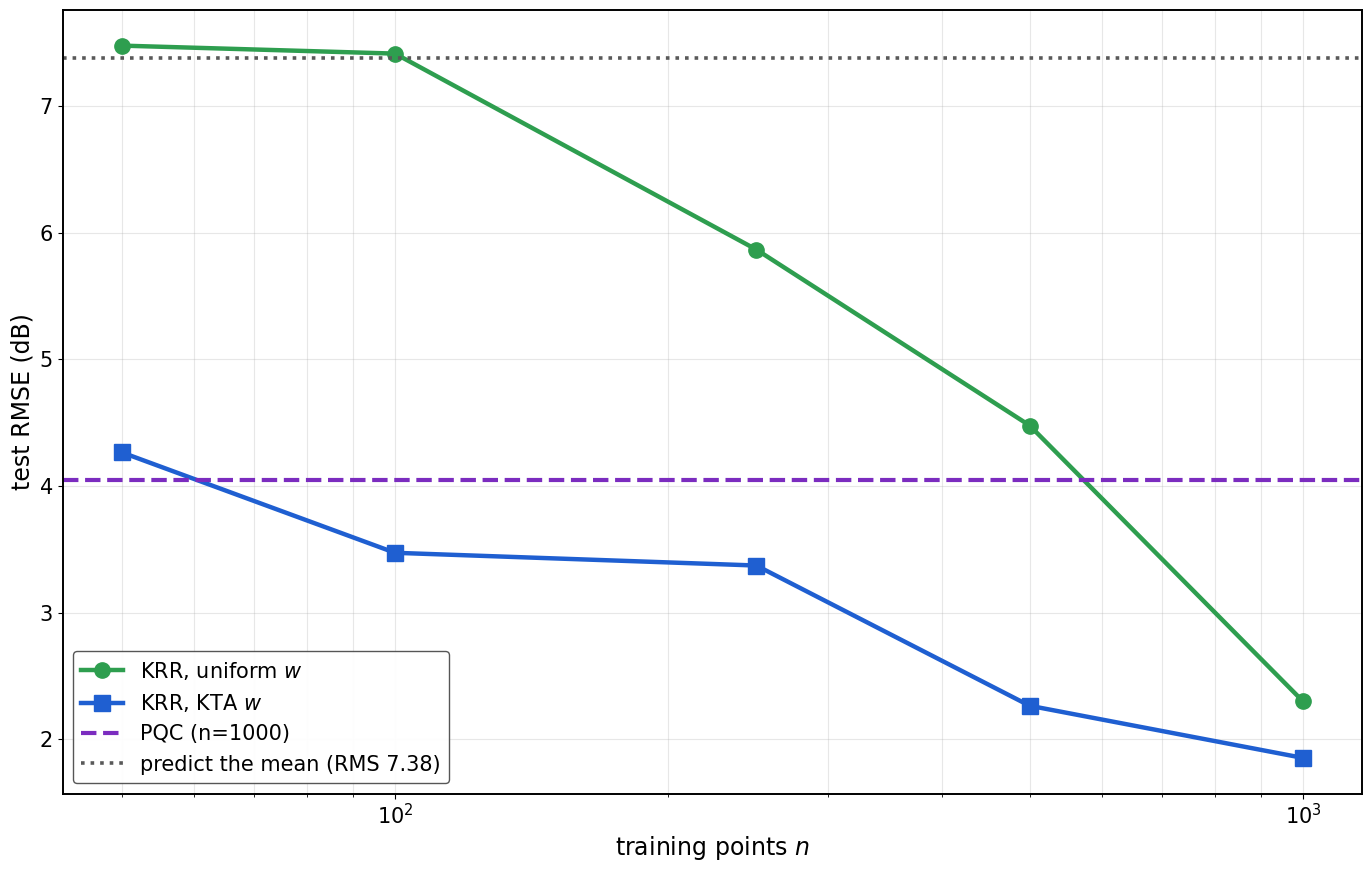

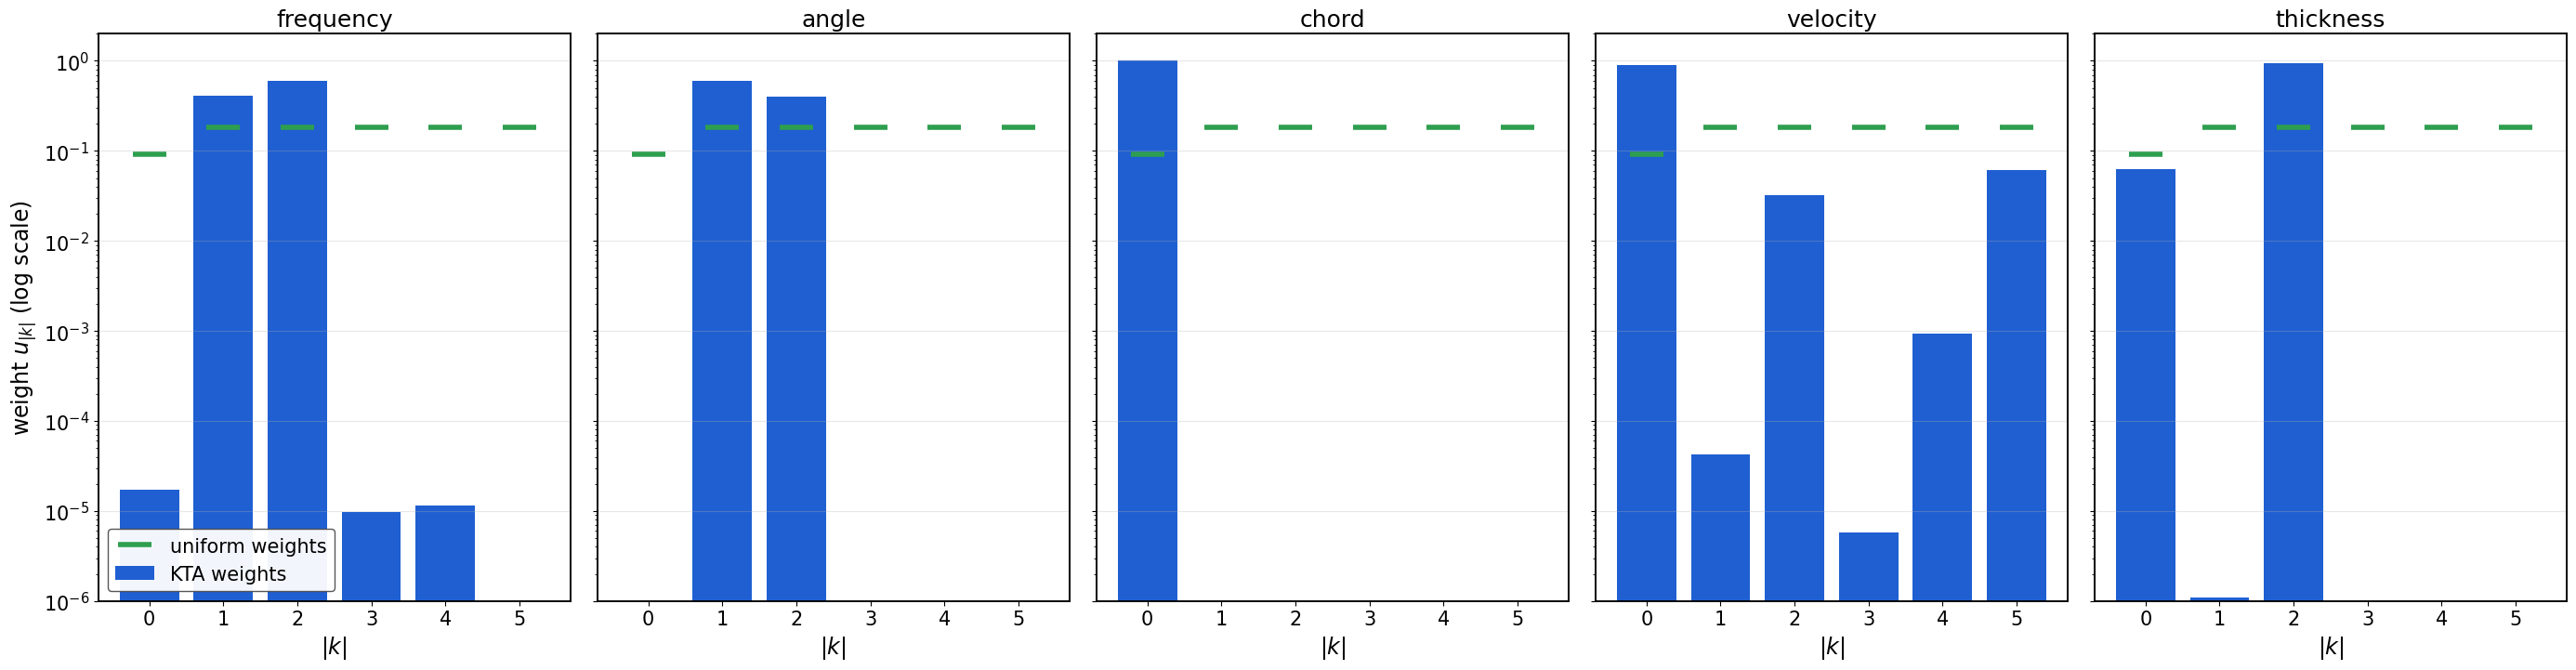

min / max predicted value over all models: 104.13 140.05364701651527 (all >= 0: True )


In [12]:
# R^2 = 1 - SSE / SST on the test set (invariant to the [-1, 1] rescaling); SST uses the test-set mean
r2 = lambda p, t: float(1 - np.sum((np.asarray(p) - t) ** 2) / np.sum((t - np.mean(t)) ** 2))
r2_from_rmse = lambda e: 1 - e ** 2 / np.var(yte)
print("test R^2:  PQC {:.3f} | KRR uniform {:.3f} | KRR KTA {:.3f} | KRR RBF {:.3f}".format(
      r2(pqc_pred_te, yte), r2(uni["pred"], yte), r2(kta["pred"], yte), r2(rbf["pred"], yte)))

# (a) predicted vs true on the test set (all values in sound pressure level, target units)
fig, axs = plt.subplots(1, 3, figsize=(27, 9), sharex=True, sharey=True)
for ax, (name, pred, col) in zip(axs, [("PQC", pqc_pred_te, PQC_COLOR),
                                       ("KRR, uniform $w$", uni["pred"], KRR_UNI_COLOR),
                                       ("KRR, KTA $w$", kta["pred"], KRR_COLOR)]):
    ax.scatter(to_price(yte), to_price(pred), s=26, alpha=0.65, color=col, edgecolor="none", label=name)
    ax.plot([ymin, ymax], [ymin, ymax], "k--", lw=2.2, label="perfect prediction")
    ax.set_title(f"{name}\n$R^2$ = {r2(pred, yte):.3f}")
    ax.set_xlabel("true sound pressure level (dB)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", markerscale=2)
axs[0].set_ylabel("predicted sound pressure level (dB)")
fig.tight_layout(); fig.savefig(f"figures/{PREFIX}_fits.pdf", bbox_inches="tight"); fig.savefig(f"figures/{PREFIX}_fits.png", dpi=200, bbox_inches="tight")

# (b) learning curve
ns = [s[0] for s in sweep_res]
fig, ax = plt.subplots(figsize=(14, 9))
ax.plot(ns, [to_units(s[1]) for s in sweep_res], "o-", color=KRR_UNI_COLOR, lw=3.2, ms=11, label="KRR, uniform $w$")
ax.plot(ns, [to_units(s[2]) for s in sweep_res], "s-", color=KRR_COLOR, lw=3.2, ms=11, label="KRR, KTA $w$")
ax.axhline(to_units(pqc_res["test_rmse"]), color=PQC_COLOR, ls="--", lw=3, label=f"PQC (n={N_TRAIN})")
base_rmse = to_units(rmse(yte, ytr.mean()))
ax.axhline(base_rmse, color="0.35", ls=":", lw=2.6, label=f"predict the mean (RMS {base_rmse:.2f})")
ax.set_xscale("log"); ax.set_xlabel("training points $n$"); ax.set_ylabel("test RMSE (dB)")
ax.grid(alpha=0.3, which="both"); ax.legend(loc="best")
fig.tight_layout(); fig.savefig(f"figures/{PREFIX}_learning_curve.pdf", bbox_inches="tight"); fig.savefig(f"figures/{PREFIX}_learning_curve.png", dpi=200, bbox_inches="tight")

# (c) learned frequency weights per feature (KRR with KTA-learned w -> blue)
fig, axs = plt.subplots(1, D, figsize=(5.6 * D, 7.5), sharey=True)
ks_ = np.arange(L + 1)
for j, ax in enumerate(axs):
    u = np.exp(kta_logits[j]); u = u / u.sum()
    ax.bar(ks_, u, color=KRR_COLOR, label="KTA weights")
    ax.plot(ks_, [1/(2*L+1)] + [2/(2*L+1)] * L, "_", color=KRR_UNI_COLOR, ms=26, mew=4, label="uniform weights")
    ax.set_yscale("log"); ax.set_ylim(1e-6, 2)
    ax.set_title(FEATURES[j]); ax.set_xlabel("$|k|$")
    ax.grid(alpha=0.3, axis="y")
axs[0].set_ylabel("weight $u_{|k|}$ (log scale)")
axs[0].legend(loc="lower left")
fig.tight_layout(); fig.savefig(f"figures/{PREFIX}_kta_weights.pdf", bbox_inches="tight"); fig.savefig(f"figures/{PREFIX}_kta_weights.png", dpi=200, bbox_inches="tight")
plt.show()

allp = np.concatenate([to_price(pqc_pred_te), to_price(uni["pred"]), to_price(kta["pred"])])
print("min / max predicted value over all models:", allp.min(), allp.max(), "(all >= 0:", bool((allp >= 0).all()), ")")

with open(f"figures/{PREFIX}_results.json", "w") as f:
    json.dump(dict(config=dict(D=D, L=L, features=FEATURES, n_train=N_TRAIN, n_val=N_VAL, n_test=N_TEST,
                               n_kta=N_KTA, kta_restarts=KTA_RESTARTS, pqc_steps=PQC_STEPS, seed=SEED),
                   rmse_scaled={"pqc": pqc_res["test_rmse"], "krr_uniform": uni["test_rmse"],
                                "krr_kta": kta["test_rmse"], "krr_rbf": rbf["test_rmse"]},
                   rmse_target_units={"pqc": to_units(pqc_res["test_rmse"]), "krr_uniform": to_units(uni["test_rmse"]),
                                      "krr_kta": to_units(kta["test_rmse"]), "krr_rbf": to_units(rbf["test_rmse"])},
                   r2={"pqc": r2(pqc_pred_te, yte), "krr_uniform": r2(uni["pred"], yte), "krr_kta": r2(kta["pred"], yte), "krr_rbf": r2(rbf["pred"], yte)},
                   alignment={"uniform": uni["align"], "kta": kta["align"]},
                   sweep=sweep_res, kta_logits=kta_logits.tolist()), f, indent=2)